Look at the data

In [1]:
import pandas as pd
df = pd.read_csv("nvda_data.csv")
print(df.columns)
df.head()

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')


,Date,Close,High,Low,Open,Volume
0,2016-01-04,0.788626,0.793742,0.780586,0.786677,358076000
1,2016-01-05,0.801295,0.814694,0.791793,0.803487,490272000
2,2016-01-06,0.768161,0.791793,0.759147,0.788139,449344000
3,2016-01-07,0.737707,0.754031,0.727962,0.748914,645304000
4,2016-01-08,0.721871,0.747940,0.720410,0.747209,398472000


Made this Date column into the datetime datatype & made Date column as an Index 

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt

#Load csv data we save earlier
df = pd.read_csv("nvda_data.csv")

#Convert date column to actual datetime type (omportant for time series work)
df['Date'] = pd.to_datetime(df['Date'])

#Set date as the index (standard practice for time series data)
df.set_index('Date', inplace=True)

print(df.shape)
df.head()

(2669, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2016-01-04,0.788626,0.793742,0.780586,0.786677,358076000
2016-01-05,0.801295,0.814694,0.791793,0.803487,490272000
2016-01-06,0.768161,0.791793,0.759147,0.788139,449344000
2016-01-07,0.737707,0.754031,0.727962,0.748914,645304000
2016-01-08,0.721871,0.747940,0.720410,0.747209,398472000


Show How NVDA data looks like

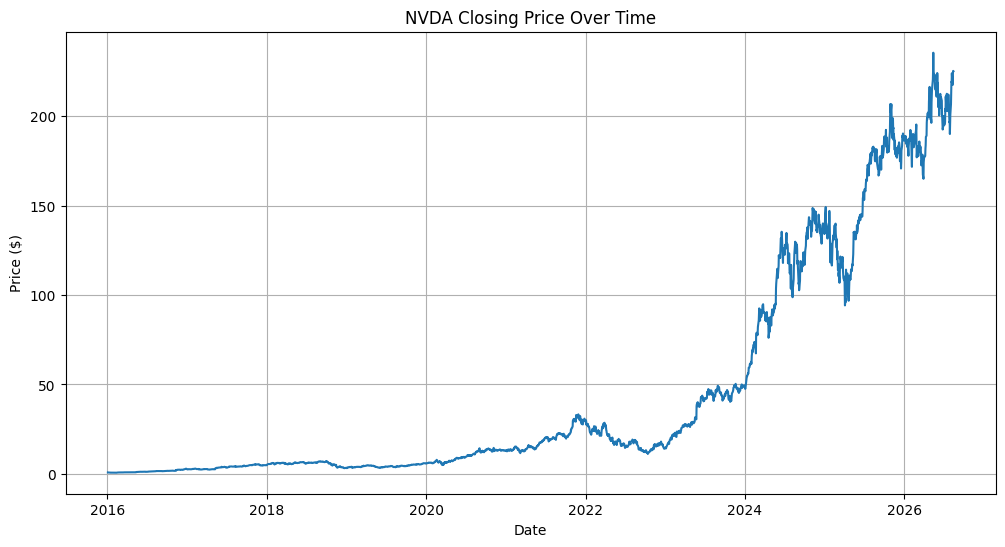

In [3]:
plt.figure(figsize=(12,6))
plt.plot(df.index, df['Close'])
plt.title('NVDA Closing Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(True)
plt.show()

Calculate daily returns in %


In [4]:
# Calculate daily returns (percentage change)
df['Return'] = df['Close'].pct_change()

# Drop the first row (it will be NaN since there's no previous day to compare)
df.dropna(subset=['Return'], inplace=True)

print(df[['Close', 'Return']].head())

               Close    Return
Date                          
2016-01-05  0.801295  0.016064
2016-01-06  0.768161 -0.041350
2016-01-07  0.737707 -0.039645
2016-01-08  0.721871 -0.021466
2016-01-11  0.723090  0.001688


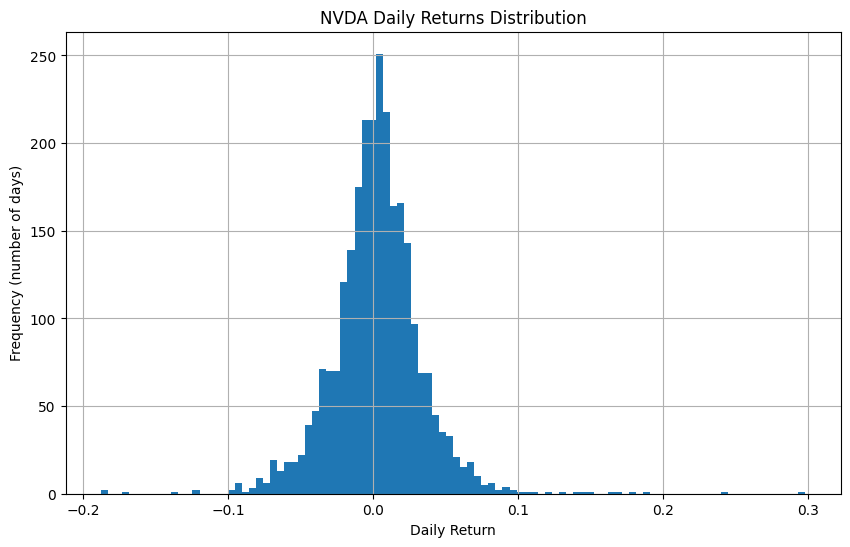

In [5]:
plt.figure(figsize=(10,6))
plt.hist(df['Return'], bins=100)
plt.title('NVDA Daily Returns Distribution')
plt.xlabel('Daily Return')
plt.ylabel('Frequency (number of days)')
plt.grid(True)
plt.show()

In [6]:
from statsmodels.tsa.stattools import adfuller

# Test on raw Close price
result_price = adfuller(df['Close'])
print("ADF test on Close price:")
print(f"  Test Statistic: {result_price[0]:.4f}")
print(f"  p-value: {result_price[1]:.4f}")

# Test on Returns
result_return = adfuller(df['Return'])
print("\nADF test on Returns:")
print(f"  Test Statistic: {result_return[0]:.4f}")
print(f"  p-value: {result_return[1]:.4f}")

ADF test on Close price:
  Test Statistic: 1.8374
  p-value: 0.9984

ADF test on Returns:
  Test Statistic: -18.7044
  p-value: 0.0000
